
### 0. Введение и подготовка данных

**Цель работы:** исследовать влияние ранга и обусловленности матрицы данных на численное решение задачи наименьших квадратов; сопоставить прямой, итерационный и спектральный способы решения; изучить действие сокращения размерности и регуляризации.

**Набор данных:** QSAR Aquatic Toxicity (UCI Machine Learning Repository).

Источник: https://archive.ics.uci.edu/dataset/505/qsar+aquatic+toxicity

Датасет содержит 546 органических соединений, описанных восемью количественными молекулярными дескрипторами. Целевая переменная характеризует острую токсичность соединений по отношению к *Daphnia magna* за 48 часов и выражается как $-\log_{10}(LC_{50})$, где $LC_{50}$ — концентрация, вызывающая гибель 50% исследуемых организмов, в моль/л.

**Используемые переменные:**

| Переменная | Описание |
|---|---|
| `TPSA(Tot)` | Топологическая площадь полярной поверхности молекулы |
| `SAacc` | Дескриптор поверхности акцепторов водородных связей |
| `H-050` | Атомно-центрированный фрагментный дескриптор, связанный с атомами водорода при гетероатомах |
| `MLOGP` | Оценка липофильности (коэффициента распределения октанол/вода) по модели Моригучи |
| `RDCHI` | Топологический индекс молекулярной связности |
| `GATS1p` | Двумерный автокорреляционный дескриптор Гири, взвешенный по поляризуемости |
| `nN` | Число атомов азота в молекуле |
| `C-040` | Атомно-центрированный фрагментный дескриптор углеродсодержащих групп |
| `LC50` | Целевая переменная: $-\log_{10}(LC_{50}\,[\mathrm{mol/L}])$ |

Все восемь признаков являются вещественными количественными переменными. Согласно описанию UCI, исходный набор не содержит пропущенных значений.

**Задача:** построить линейную регрессионную модель для предсказания токсичности соединений по молекулярным дескрипторам. Основная метрика качества прогноза — RMSE на тестовой выборке.

**Библиографическая ссылка на набор данных:**

Ballabio D., Cassotti M., Consonni V., Todeschini R. (2014). *QSAR aquatic toxicity*. UCI Machine Learning Repository. https://doi.org/10.24432/C5SG7H

**Статья, описывающая исходное исследование:**

Cassotti M. et al. (2014). Prediction of acute aquatic toxicity towards Daphnia magna using GA-kNN method. *Alternatives to Laboratory Animals*, 42, 31–41. https://doi.org/10.1177/026119291404200106


#### 0.1. Загрузка и первичный анализ данных

Для обеспечения воспроизводимости предусмотрены два способа загрузки набора QSAR Aquatic Toxicity:

1. Если файл `qsar_aquatic_toxicity_clean.csv` находится в рабочей директории, используется локальная копия.
2. При отсутствии файла данные автоматически загружаются из UCI Machine Learning Repository. Исходному CSV назначаются названия столбцов.

После загрузки проверим размерность набора (546 наблюдений, 8 признаков и целевая переменная), соответствие названий столбцов и отсутствие пропущенных значений.

Затем изучим типы переменных и основные описательные статистики.

Матрица исходных признаков имеет размерность:

$$
X \in \mathbb{R}^{n \times p},
$$

а вектор целевой переменной:

$$
y \in \mathbb{R}^{n}.
$$

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
from urllib.error import URLError

DATA_PATH = Path("qsar_aquatic_toxicity_clean.csv")

COLUMNS = [
    "TPSA(Tot)", "SAacc", "H-050", "MLOGP",
    "RDCHI", "GATS1p", "nN", "C-040", "LC50"
]

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print("Источник: локальный CSV")

else:
    url = (
        "https://archive.ics.uci.edu/static/public/505/"
        "qsar%2Baquatic%2Btoxicity.zip"
    )

    try:
        with urlopen(url, timeout=15) as response:
            archive_data = BytesIO(response.read())

        with ZipFile(archive_data) as archive:
            csv_name = next(
                name for name in archive.namelist()
                if name.lower().endswith(".csv")
            )

            with archive.open(csv_name) as csv_file:
                df = pd.read_csv(
                    csv_file,
                    sep=";",
                    header=None,
                    names=COLUMNS
                )

        # Сохраняем данные для последующих запусков
        df.to_csv(DATA_PATH, index=False)
        print("Источник: UCI. Локальная копия сохранена.")

    except (URLError, TimeoutError) as e:
        raise RuntimeError(
            "Не удалось загрузить данные из UCI. "
            "Поместите файл qsar_aquatic_toxicity_clean.csv "
            "в рабочую директорию ноутбука."
        ) from e

# Проверяем структуру данных
assert df.shape == (546, 9)
assert list(df.columns) == COLUMNS
assert df.notna().all().all()

# Воспроизводимость экспериментов
RANDOM_STATE = 42

print(f"Размер датасета: {df.shape}")
print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isna().sum())

display(df.head())
display(df.describe().T)

Источник: локальный CSV
Размер датасета: (546, 9)

Типы данных:
TPSA(Tot)    float64
SAacc        float64
H-050          int64
MLOGP        float64
RDCHI        float64
GATS1p       float64
nN             int64
C-040          int64
LC50         float64
dtype: object

Количество пропусков:
TPSA(Tot)    0
SAacc        0
H-050        0
MLOGP        0
RDCHI        0
GATS1p       0
nN           0
C-040        0
LC50         0
dtype: int64


,TPSA(Tot),SAacc,H-050,MLOGP,RDCHI,GATS1p,nN,C-040,LC50
0,0.00,0.0,0,2.419,1.225,0.667,0,0,3.740
1,0.00,0.0,0,2.638,1.401,0.632,0,0,4.330
2,9.23,11.0,0,5.799,2.930,0.486,0,0,7.019
3,9.23,11.0,0,5.453,2.887,0.495,0,0,6.723
4,9.23,11.0,0,4.068,2.758,0.695,0,0,5.979


,count,mean,std,min,25%,50%,75%,max
TPSA(Tot),546.0,48.472930,46.763983,0.000,15.7900,40.4600,70.02250,347.320
SAacc,546.0,58.869018,68.166554,0.000,11.0000,42.6830,77.49275,571.952
H-050,546.0,0.937729,1.618632,0.000,0.0000,0.0000,1.00000,18.000
MLOGP,546.0,2.313493,1.741797,-6.446,1.2325,2.2735,3.39275,9.148
RDCHI,546.0,2.492299,0.811004,1.000,1.9750,2.3440,2.91100,6.439
GATS1p,546.0,1.046264,0.403677,0.281,0.7370,1.0205,1.26650,2.500
nN,546.0,1.003663,1.397240,0.000,0.0000,1.0000,2.00000,11.000
C-040,546.0,0.353480,0.806827,0.000,0.0000,0.0000,0.00000,11.000
LC50,546.0,4.658421,1.665215,0.122,3.6015,4.5160,5.60750,10.047


#### 0.2. Разделение выборки и стандартизация признаков

Исходные данные разделяются на обучающую (80%) и тестовую (20%) выборки. Для воспроизводимости экспериментов фиксируется random_state=42. Одно и то же разбиение используется для всех последующих методов.

Поскольку молекулярные дескрипторы имеют различные масштабы, выполняется **стандартизация количественных признаков**:

$$
x_{ij}^{\mathrm{std}} =
\frac{x_{ij}-\mu_j}{\sigma_j},
$$

где:

- $x_{ij}$ — значение $j$-го признака для $i$-го наблюдения;
- $\mu_j$ — среднее значение $j$-го признака на обучающей выборке;
- $\sigma_j$ — стандартное отклонение $j$-го признака на обучающей выборке.

После стандартизации каждый невыражденный в константу признак обучающей выборки имеет нулевое среднее и единичную дисперсию. Для тестовой выборки используются те же значения $\mu_j$ и $\sigma_j$, что исключает утечку информации.

Для учёта свободного члена $\beta_0$ к матрице признаков добавляется столбец единиц:

$$
\widetilde{X} =
\begin{pmatrix}
1 & x_{11} & \cdots & x_{1p}\\
1 & x_{21} & \cdots & x_{2p}\\
\vdots & \vdots & \ddots & \vdots\\
1 & x_{n1} & \cdots & x_{np}
\end{pmatrix}.
$$

Таким образом, вектор параметров модели принимает вид:

$$
\beta = (\beta_0,\beta_1,\ldots,\beta_p)^T.
$$

Столбец свободного члена не стандартизируется и впоследствии не подвергается Ridge-регуляризации.

In [5]:
# Определяем признаки и целевую переменную
TARGET = "LC50"
FEATURES = [col for col in df.columns if col != TARGET]

X = df[FEATURES].to_numpy(dtype=float)
y = df[TARGET].to_numpy(dtype=float)

assert np.isfinite(X).all()
assert np.isfinite(y).all()

# Разделяем данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# Стандартизация по обучающей выборке
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

# Добавляем столбец единиц для свободного члена
X_train_raw = np.column_stack([
    np.ones(len(X_train)), X_train
])

X_train_design = np.column_stack([
    np.ones(len(X_train_std)), X_train_std
])

X_test_design = np.column_stack([
    np.ones(len(X_test_std)), X_test_std
])

# Проверяем размеры
print("Train:", X_train_design.shape)
print("Test: ", X_test_design.shape)
print("Количество коэффициентов:", X_train_design.shape[1])

Train: (436, 9)
Test:  (110, 9)
Количество коэффициентов: 9



### 1. Исследование матрицы данных


#### 1.1. Ранг, сингулярные числа и обусловленность

Для исходной и стандартизованной матриц исследуем их ранг, сингулярные числа и числа обусловленности.

**Сингулярное разложение (SVD)** представляет матрицу $X$ в виде:

$$
X=U\Sigma V^T,
$$

где $U$ и $V$ — матрицы с ортонормированными столбцами, а $\Sigma$ содержит неотрицательные **сингулярные числа** $\sigma_i$, упорядоченные по убыванию. Они характеризуют растяжение пространства матрицей $X$ вдоль соответствующих направлений и связаны с собственными значениями матрицы $X^TX$:

$$
\sigma_i=\sqrt{\lambda_i(X^TX)}.
$$

**Ранг матрицы** равен числу ненулевых сингулярных чисел. Поскольку вычисления выполняются с конечной точностью, для определения численного ранга используем допуск:

$$
\tau=\max(n,p)\,\varepsilon_{\mathrm{mach}}\,\sigma_{\max},
$$

где $\varepsilon_{\mathrm{mach}}$ — машинная точность. Численный ранг определяется количеством сингулярных чисел, превышающих $\tau$:

$$
r=\#\{\sigma_i>\tau\}.
$$

**Число обусловленности** характеризует чувствительность задачи к малым возмущениям:

$$
\kappa_2(X)=\frac{\sigma_{\max}}{\sigma_{\min}}.
$$

При полном столбцовом ранге выполняется:

$$
\kappa_2(X^TX)=\kappa_2(X)^2.
$$

Таким образом, переход к нормальным уравнениям увеличивает число обусловленности в квадрат, что может снижать численную устойчивость решения. При потере ранга число обусловленности становится бесконечным.

Сравним эти характеристики до и после стандартизации признаков.



In [6]:

def matrix_diagnostics(X):
    # Сингулярные числа
    s = np.linalg.svd(X, compute_uv=False)

    # Допуск и численный ранг
    tol = max(X.shape) * np.finfo(float).eps * s[0]
    rank = np.sum(s > tol)

    # Матрица нормальных уравнений
    A = X.T @ X

    return {
        "rank": rank,
        "tol": tol,
        "singular_values": s,
        "cond_X": np.linalg.cond(X),
        "cond_A": np.linalg.cond(A)
    }


# Диагностика двух матриц
diag_raw = matrix_diagnostics(X_train_raw)
diag_std = matrix_diagnostics(X_train_design)

# Сводная таблица
diagnostics = pd.DataFrame({
    "Исходная матрица": [
        diag_raw["rank"],
        diag_raw["tol"],
        diag_raw["cond_X"],
        diag_raw["cond_A"]
    ],
    "Стандартизованная матрица": [
        diag_std["rank"],
        diag_std["tol"],
        diag_std["cond_X"],
        diag_std["cond_A"]
    ]
}, index=[
    "Численный ранг",
    "Допуск",
    "κ₂(X)",
    "κ₂(XᵀX)"
])

display(diagnostics)

# Таблица сингулярных чисел
singular_values = pd.DataFrame({
    "Исходная": diag_raw["singular_values"],
    "Стандартизованная": diag_std["singular_values"]
}, index=np.arange(1, X_train_design.shape[1] + 1))

display(singular_values)


,Исходная матрица,Стандартизованная матрица
Численный ранг,9.000000e+00,9.000000e+00
Допуск,2.366294e-10,3.926471e-12
κ₂(X),6.053662e+02,7.078080e+00
κ₂(XᵀX),3.664682e+05,5.009922e+01


,Исходная,Стандартизованная
1,2444.229980,40.557917
2,456.936899,25.540283
3,66.854678,21.182407
4,25.729356,20.880613
5,21.681996,17.213486
6,15.573511,16.022523
7,13.714548,10.718602
8,6.318460,6.427088
9,4.037606,5.730073



#### 1.2. Спектр сингулярных чисел

Для визуального сравнения построим спектры сингулярных чисел исходной и стандартизованной матриц.

Большой разброс между максимальным и минимальным сингулярными числами свидетельствует о плохой обусловленности. Значения, близкие к нулю, указывают на возможную линейную зависимость признаков.


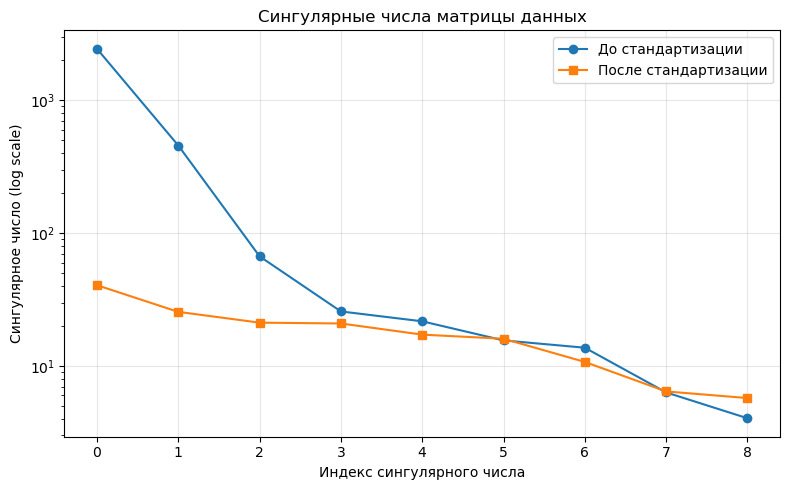

In [7]:
plt.figure(figsize=(8, 5))

plt.semilogy(
    diag_raw["singular_values"],
    "o-",
    label="До стандартизации"
)

plt.semilogy(
    diag_std["singular_values"],
    "s-",
    label="После стандартизации"
)

plt.xlabel("Индекс сингулярного числа")
plt.ylabel("Сингулярное число (log scale)")
plt.title("Сингулярные числа матрицы данных")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



#### 1.3. Корреляционный анализ признаков

Для выявления линейных зависимостей между признаками вычислим коэффициенты корреляции Пирсона:

$$
r_{jk} =
\frac{\operatorname{cov}(x_j,x_k)}
{\sigma_j\sigma_k}.
$$

Значения $|r_{jk}|$, близкие к 1, указывают на сильную линейную связь между двумя признаками и возможную мультиколлинеарность.

Рассмотрим корреляционные матрицы до и после стандартизации. Поскольку стандартизация представляет собой линейное преобразование с положительным масштабным коэффициентом, корреляции Пирсона при этом не изменяются.


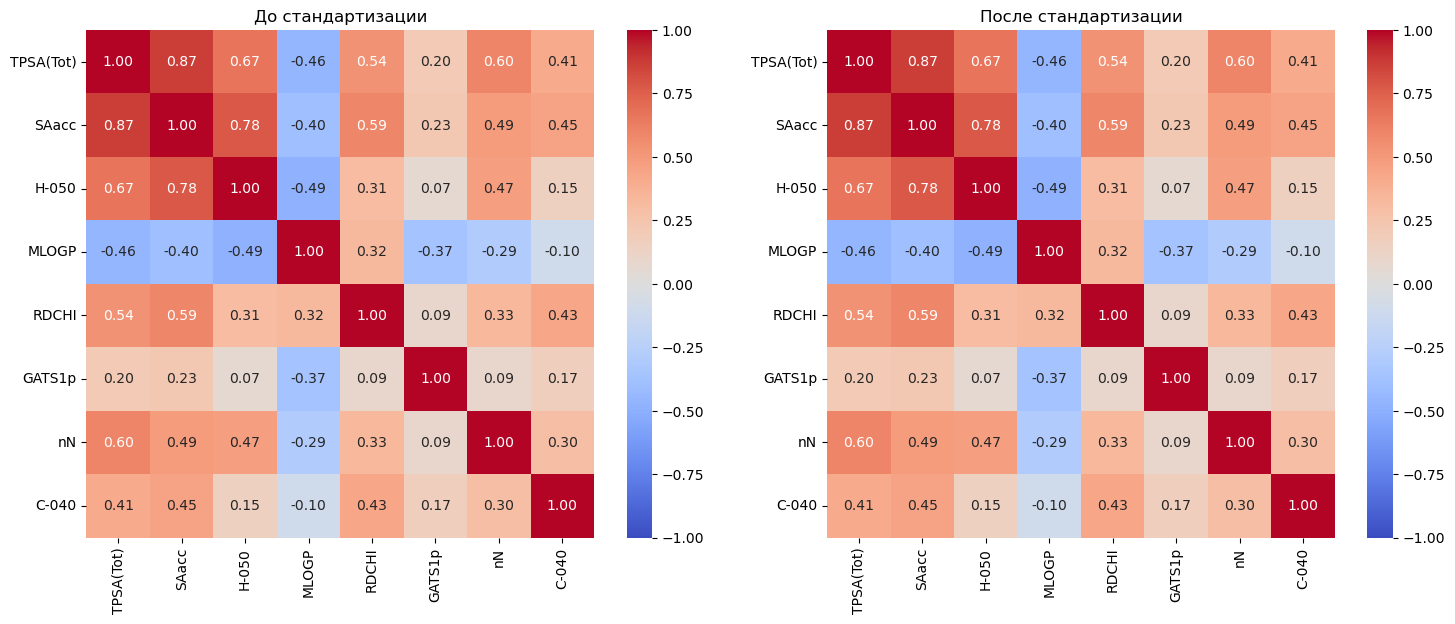

Максимальное изменение корреляции: 7.771561172376096e-16


In [8]:
# Корреляционные матрицы количественных признаков
corr_raw = pd.DataFrame(
    X_train, columns=FEATURES
).corr()

corr_std = pd.DataFrame(
    X_train_std, columns=FEATURES
).corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, corr, title in zip(
    axes,
    [corr_raw, corr_std],
    ["До стандартизации", "После стандартизации"]
):
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        square=True,
        ax=ax
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Проверяем неизменность корреляций
print(
    "Максимальное изменение корреляции:",
    np.max(np.abs(corr_raw.values - corr_std.values))
)



#### 1.4. Выводы

Исходная и стандартизованная матрицы имеют полный столбцовый ранг $r=9$. Все сингулярные числа значительно превышают соответствующие численные допуски, что свидетельствует об отсутствии точной линейной зависимости между столбцами.

Стандартизация существенно улучшила обусловленность матрицы: $\kappa_2(X)$ уменьшилось с $605.37$ до $7.08$, а $\kappa_2(X^TX)$ — с $3.66\cdot10^5$ до $50.10$. Это согласуется с теоретическим соотношением $\kappa_2(X^TX)=\kappa_2(X)^2$.

Корреляционный анализ выявил сильные связи между некоторыми молекулярными дескрипторами, в частности `TPSA(Tot)` и `SAacc` ($r=0.87$). При этом стандартизация не изменила корреляционную структуру данных ($\Delta r_{\max}=7.77\cdot10^{-16}$).

Таким образом, исходная матрица характеризуется значительным разбросом масштабов и наличием коррелирующих признаков. Стандартизация уменьшает число обусловленности и создаёт более благоприятные условия для численного решения МНК.



### 2. Прямое решение нормальных уравнений

#### 2.1. Метод LU-разложения

Задача наименьших квадратов имеет вид:

$$
\min_{\beta}\|X\beta-y\|_2^2.
$$

Её решение при полном столбцовом ранге матрицы $X$ можно найти из **нормальных уравнений**:

$$
A\beta=b,\qquad A=X^TX,\quad b=X^Ty.
$$

Для решения системы используем **LU-разложение с частичным выбором ведущего элемента**:

$$
PA=LU,
$$

где $P$ — матрица перестановок, $L$ — нижняя треугольная, $U$ — верхняя треугольная матрица.

Решение получается последовательным решением двух треугольных систем:

$$
Lz=Pb,\qquad U\beta=z.
$$

Для оценки точности вычислим:

- **Относительный остаток нормальных уравнений:**

$$
r_{\mathrm{NE}}=\frac{\|A\beta-b\|_2}{\|b\|_2}.
$$

- **Относительный остаток задачи МНК:**

$$
r_{\mathrm{LS}}=\frac{\|X\beta-y\|_2}{\|y\|_2}.
$$

- **RMSE** на обучающей и тестовой выборках:

$$
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}.
$$

Вычисления проводятся для стандартизованной матрицы признаков с учётом свободного члена.


In [9]:

from scipy.linalg import lu_factor, lu_solve

# Формирование нормальных уравнений
X = X_train_design

A = X.T @ X
b = X.T @ y_train

# LU-разложение с частичным выбором ведущего элемента
lu, piv = lu_factor(A)

# Решение системы
beta_lu = lu_solve((lu, piv), b)

# Функция для оценки решений МНК
def evaluate_solution(beta):
    r_ne = np.linalg.norm(A @ beta - b) / np.linalg.norm(b)
    r_ls = np.linalg.norm(X @ beta - y_train) / np.linalg.norm(y_train)

    y_pred_train = X_train_design @ beta
    y_pred_test = X_test_design @ beta

    rmse_train = np.sqrt(np.mean((y_train - y_pred_train)**2))
    rmse_test = np.sqrt(np.mean((y_test - y_pred_test)**2))

    return {
        "r_NE": r_ne,
        "r_LS": r_ls,
        "RMSE_train": rmse_train,
        "RMSE_test": rmse_test
    }

# Результаты LU
print("Коэффициенты LU:")
display(pd.Series(
    beta_lu,
    index=["Intercept"] + FEATURES
))

print("Метрики LU:")
display(pd.Series(evaluate_solution(beta_lu)))


Коэффициенты LU:


Intercept    4.694101
TPSA(Tot)    1.363363
SAacc       -1.135084
H-050        0.118256
MLOGP        0.792054
RDCHI        0.376816
GATS1p      -0.276501
nN          -0.312998
C-040        0.067012
dtype: float64

Метрики LU:


r_NE          1.140120e-16
r_LS          2.395221e-01
RMSE_train    1.192644e+00
RMSE_test     1.208936e+00
dtype: float64


 Методом LU-разложения получены коэффициенты линейной регрессии. Относительный остаток нормальных уравнений составил $r_{\mathrm{NE}}=1.14\cdot10^{-16}$, что свидетельствует о высокой численной точности решения. Ошибки прогноза на обучающей и тестовой выборках близки: RMSE = 1.193 и 1.209 соответственно. Это указывает на отсутствие выраженного разрыва между качеством модели на обучающих и тестовых данных.



#### 2.2. Разложение Холецкого

Для симметричной положительно определённой матрицы $A$ существует **разложение Холецкого**:

$$
A=LL^T,
$$

где $L$ — нижняя треугольная матрица с положительными диагональными элементами.

В нашем случае $A=X^TX$ симметрична. Поскольку матрица $X$ имеет полный столбцовый ранг, $A$ также положительно определена:

$$
v^TAv=v^TX^TXv=\|Xv\|_2^2>0,\qquad v\neq0.
$$

Для решения системы $A\beta=b$ последовательно решаются две треугольные системы:

$$
Lz=b,\qquad L^T\beta=z.
$$

**Для оценки точности решения вычислим следующие метрики:**

1. **Относительный остаток нормальных уравнений** — характеризует точность решения системы $A\beta=b$:

$$
r_{\mathrm{NE}}=\frac{\|A\beta-b\|_2}{\|b\|_2}.
$$

2. **Относительный остаток задачи МНК** — характеризует отклонение предсказаний от наблюдаемых значений:

$$
r_{\mathrm{LS}}=\frac{\|X\beta-y\|_2}{\|y\|_2}.
$$

3. **Среднеквадратичная ошибка (RMSE)** — оценивает качество прогнозирования на обучающей и тестовой выборках:

$$
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}.
$$

Дополнительно сравним коэффициенты, полученные методами Холецкого и LU, с помощью евклидовой нормы их разности:

$$
\Delta_\beta=\|\beta_{\mathrm{LU}}-\beta_{\mathrm{Cholesky}}\|_2.
$$

Малое значение $\Delta_\beta$ свидетельствует о близости найденных решений.


In [10]:

from scipy.linalg import cho_factor, cho_solve

try:
    # Разложение Холецкого
    c, lower = cho_factor(A, lower=True)

    # Решение нормальных уравнений
    beta_chol = cho_solve((c, lower), b)

    print("Разложение Холецкого успешно выполнено.")

    # Оценка решения
    print("\nМетрики Холецкого:")
    display(pd.Series(evaluate_solution(beta_chol)))

    # Сравнение с LU
    print("\nНорма разности коэффициентов LU и Холецкого:")
    print(np.linalg.norm(beta_lu - beta_chol))

except np.linalg.LinAlgError as e:
    beta_chol = None
    print("Разложение Холецкого невозможно:", e)


Разложение Холецкого успешно выполнено.

Метрики Холецкого:


r_NE          1.432983e-16
r_LS          2.395221e-01
RMSE_train    1.192644e+00
RMSE_test     1.208936e+00
dtype: float64


Норма разности коэффициентов LU и Холецкого:
7.889616961715915e-16



Разложение Холецкого успешно выполнено, что подтверждает положительную определённость матрицы $A=X^TX$. Полученные коэффициенты практически совпадают с результатами LU: норма их разности составляет $7.89\cdot10^{-16}$. Относительные остатки нормальных уравнений имеют порядок $10^{-16}$, а значения RMSE полностью совпадают с точностью до представленных знаков. Таким образом, оба метода обеспечивают высокую численную точность решения исследуемой системы.



#### 2.3. Сравнение с библиотечным решением МНК

Для проверки результатов используем функцию `numpy.linalg.lstsq`, которая решает исходную задачу МНК:

$$
\hat{\beta}=\arg\min_{\beta}\|X\beta-y\|_2^2
$$

без явного формирования нормальных уравнений $X^TX\beta=X^Ty$. Такой подход позволяет избежать возведения числа обусловленности матрицы в квадрат.

Сравним решения LU, Холецкого и `lstsq` по коэффициентам, относительным остаткам и RMSE. Дополнительно вычислим относительное отклонение коэффициентов от библиотечного решения:

$$
\delta_\beta=
\frac{\|\beta_{\mathrm{method}}-\beta_{\mathrm{ref}}\|_2}
{\|\beta_{\mathrm{ref}}\|_2},
$$

где $\beta_{\mathrm{ref}}$ — коэффициенты, полученные с помощью `lstsq`.


In [11]:

# Библиотечное решение исходной задачи МНК
beta_ref, residuals, rank, s = np.linalg.lstsq(
    X_train_design, y_train, rcond=None
)

# Собираем решения для сравнения
solutions = {
    "LU": beta_lu,
    "NumPy lstsq": beta_ref
}

if beta_chol is not None:
    solutions["Cholesky"] = beta_chol

# Таблица коэффициентов
coefficients = pd.DataFrame(
    solutions,
    index=["Intercept"] + FEATURES
)

print("Коэффициенты регрессии:")
display(coefficients)

# Таблица метрик
comparison = pd.DataFrame({
    name: evaluate_solution(beta)
    for name, beta in solutions.items()
}).T

comparison["delta_beta"] = [
    np.linalg.norm(beta - beta_ref) / np.linalg.norm(beta_ref)
    for beta in solutions.values()
]

print("Сравнение методов:")
display(comparison)


Коэффициенты регрессии:


,LU,NumPy lstsq,Cholesky
Intercept,4.694101,4.694101,4.694101
TPSA(Tot),1.363363,1.363363,1.363363
SAacc,-1.135084,-1.135084,-1.135084
H-050,0.118256,0.118256,0.118256
MLOGP,0.792054,0.792054,0.792054
RDCHI,0.376816,0.376816,0.376816
GATS1p,-0.276501,-0.276501,-0.276501
nN,-0.312998,-0.312998,-0.312998
C-040,0.067012,0.067012,0.067012


Сравнение методов:


,r_NE,r_LS,RMSE_train,RMSE_test,delta_beta
LU,1.140120e-16,0.239522,1.192644,1.208936,1.739956e-15
NumPy lstsq,1.456269e-15,0.239522,1.192644,1.208936,0.000000e+00
Cholesky,1.432983e-16,0.239522,1.192644,1.208936,1.731298e-15



#### 2.4. Выводы

Методы LU, Холецкого и `numpy.linalg.lstsq` дали практически идентичные коэффициенты регрессии. Относительные отклонения коэффициентов прямых методов от библиотечного решения составили около $1.7\cdot10^{-15}$, а остатки нормальных уравнений не превысили $1.5\cdot10^{-15}$.

Все методы обеспечили одинаковое качество прогнозирования: $\mathrm{RMSE}_{train}=1.193$ и $\mathrm{RMSE}_{test}=1.209$. Это свидетельствует о численной устойчивости решения исследуемой задачи при текущей обусловленности матрицы ($\kappa_2(X^TX)\approx50.1$).



### 3. Итерационное решение нормальных уравнений

#### 3.1. Метод Зейделя

Рассмотрим систему нормальных уравнений:

$$
A\beta=b,\qquad A=X^TX,\quad b=X^Ty.
$$

В отличие от прямых методов, **метод Зейделя** строит последовательность приближений $\beta^{(0)},\beta^{(1)},\ldots$ к решению системы.

Представим матрицу $A$ в виде:

$$
A=D+L+U,
$$

где $D$ — диагональная часть, $L$ — строго нижняя треугольная, $U$ — строго верхняя треугольная часть матрицы.

Итерационная формула метода Зейделя:

$$
\beta^{(k+1)}=-(D+L)^{-1}U\beta^{(k)}+(D+L)^{-1}b.
$$

Её можно записать как:

$$
\beta^{(k+1)}=B_{\mathrm{GS}}\beta^{(k)}+c,
$$

где **итерационная матрица**:

$$
B_{\mathrm{GS}}=-(D+L)^{-1}U.
$$

Сходимость метода определяется спектральным радиусом итерационной матрицы:

$$
\rho(B_{\mathrm{GS}})=\max_i|\lambda_i(B_{\mathrm{GS}})|.
$$

Для данной стационарной итерации условие $\rho(B_{\mathrm{GS}})<1$ гарантирует сходимость к решению при любом начальном приближении. Если $\rho(B_{\mathrm{GS}})>1$, метод в общем случае расходится.

На каждой итерации будем отслеживать **относительный остаток нормальных уравнений**:

$$
r^{(k)}=\frac{\|A\beta^{(k)}-b\|_2}{\|b\|_2}.
$$

Остановим вычисления при $r^{(k)}<10^{-10}$ или достижении максимального числа итераций.


#### 3.2. Спектральный анализ и прогноз сходимости

In [12]:

from scipy.linalg import solve_triangular

# Разделение A на диагональную, нижнюю и верхнюю части
D = np.diag(np.diag(A))
L = np.tril(A, k=-1)
U = np.triu(A, k=1)

# Итерационная матрица метода Зейделя
# B_GS = -(D + L)^(-1) @ U
B_GS = -solve_triangular(D + L, U, lower=True)

# Собственные значения итерационной матрицы
eigenvalues = np.linalg.eigvals(B_GS)

# Спектральный радиус
rho_GS = np.max(np.abs(eigenvalues))

print("Собственные значения итерационной матрицы:")
display(pd.Series(eigenvalues, name="lambda"))

print(f"\nСпектральный радиус: {rho_GS:.6f}")

if rho_GS < 1:
    print("Прогноз: метод Зейделя сходится.")
else:
    print("Прогноз: сходимость для любого начального приближения не гарантирована.")


Собственные значения итерационной матрицы:


0   -0.000000+0.000000j
1    0.000000+0.000000j
2    0.843002+0.000000j
3    0.758662+0.045576j
4    0.758662-0.045576j
5   -0.074129+0.000000j
6    0.028377+0.000000j
7    0.393511+0.000000j
8    0.270971+0.000000j
Name: lambda, dtype: complex128


Спектральный радиус: 0.843002
Прогноз: метод Зейделя сходится.


Спектральный радиус итерационной матрицы метода Зейделя составляет $\rho(B_{\mathrm{GS}})=0.843002<1$, что гарантирует сходимость метода при любом начальном приближении. Поскольку спектральный радиус достаточно близок к единице, ожидается постепенное уменьшение ошибки, без быстрой сходимости за несколько итераций.



#### 3.3. Итерационное решение методом Зейделя

На каждой итерации метода Зейделя коэффициенты последовательно обновляются по формуле:

$$
\beta_i^{(k+1)}=
\frac{1}{a_{ii}}
\left(
b_i-\sum_{j<i}a_{ij}\beta_j^{(k+1)}
-\sum_{j>i}a_{ij}\beta_j^{(k)}
\right).
$$

Таким образом, при вычислении очередного коэффициента используются уже обновлённые значения предыдущих коэффициентов.

В качестве начального приближения выберем нулевой вектор $\beta^{(0)}=0$. Установим максимальное число итераций $N_{\max}=1000$ и допуск $\varepsilon=10^{-10}$.

**Критерий остановки** — достижение относительным остатком нормальных уравнений заданного допуска:

$$
r^{(k)}=\frac{\|A\beta^{(k)}-b\|_2}{\|b\|_2}<\varepsilon.
$$

Сохраним историю $r^{(k)}$ для анализа скорости сходимости и сравним полученное решение с результатом LU.


In [13]:
# Параметры итерационного метода
tol_gs = 1e-10
max_iter = 1000

# Начальное приближение
beta_gs = np.zeros_like(b)

# История относительного остатка
residual_history = []

# Начальный остаток
r0 = np.linalg.norm(A @ beta_gs - b) / np.linalg.norm(b)
residual_history.append(r0)

# Итерации метода Зейделя
for k in range(1, max_iter + 1):
    beta_old = beta_gs.copy()

    for i in range(len(b)):
        # Уже обновлённые коэффициенты
        sum_lower = A[i, :i] @ beta_gs[:i]

        # Коэффициенты предыдущей итерации
        sum_upper = A[i, i+1:] @ beta_old[i+1:]

        beta_gs[i] = (b[i] - sum_lower - sum_upper) / A[i, i]

    # Относительный остаток
    r = np.linalg.norm(A @ beta_gs - b) / np.linalg.norm(b)
    residual_history.append(r)

    if r < tol_gs:
        break

# Проверка сходимости
converged = residual_history[-1] < tol_gs

print(f"Число итераций: {k}")
print(f"Сходимость: {converged}")
print(f"Конечный относительный остаток: {residual_history[-1]:.3e}")

print("\nМетрики метода Зейделя:")
display(pd.Series(evaluate_solution(beta_gs)))

print("\nНорма разности коэффициентов Зейделя и LU:")
print(np.linalg.norm(beta_gs - beta_lu))


Число итераций: 118
Сходимость: True
Конечный относительный остаток: 8.641e-11

Метрики метода Зейделя:


r_NE          8.640753e-11
r_LS          2.395221e-01
RMSE_train    1.192644e+00
RMSE_test     1.208936e+00
dtype: float64


Норма разности коэффициентов Зейделя и LU:
3.2076576281242307e-09



Метод Зейделя сошёлся за 118 итераций, достигнув относительного остатка $r_{\mathrm{NE}}=8.64\cdot10^{-11}<10^{-10}$. Это подтверждает прогноз сходимости, основанный на спектральном радиусе $\rho(B_{\mathrm{GS}})=0.843002<1$.

Полученные коэффициенты близки к решению LU: норма их разности составляет $3.21\cdot10^{-9}$. Значения RMSE на обучающей и тестовой выборках практически совпадают с результатами прямых методов.



#### 3.4. Анализ сходимости метода Зейделя

Для исследования скорости сходимости построим зависимость относительного остатка нормальных уравнений от номера итерации:

$$
r^{(k)}=\frac{\|A\beta^{(k)}-b\|_2}{\|b\|_2}.
$$

График представим в логарифмической шкале по оси $r^{(k)}$, поскольку остаток изменяется на несколько порядков.

При $\rho(B_{\mathrm{GS}})<1$ ожидается асимптотически геометрическое уменьшение ошибки. Если доминирующее собственное значение определяет поведение итераций, отношение последовательных остатков приближается к спектральному радиусу:

$$
\frac{r^{(k+1)}}{r^{(k)}}\longrightarrow\rho(B_{\mathrm{GS}}).
$$

Сравним фактическое уменьшение остатка с теоретическим прогнозом и проверим достижение заданного допуска $\varepsilon=10^{-10}$.


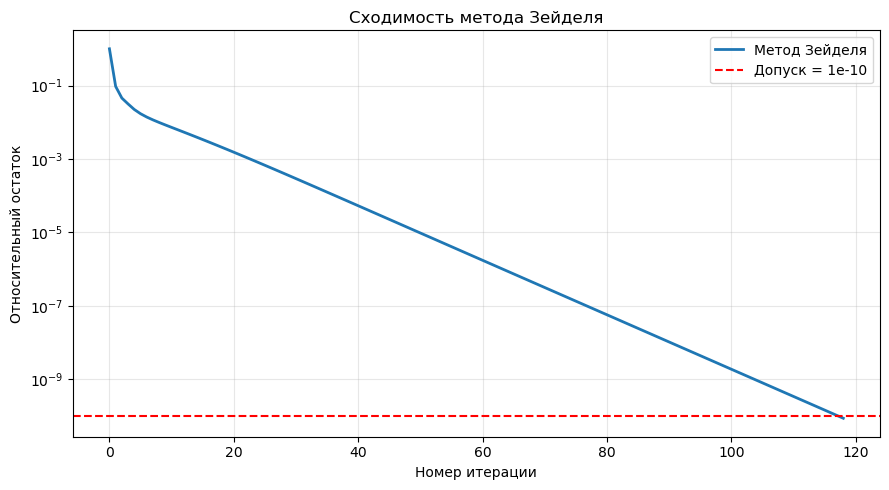

Спектральный радиус: 0.843002
Среднее отношение остатков за последние 20 итераций: 0.843003
Финальный остаток: 8.641e-11
Количество итераций: 118


In [14]:
# Номера итераций, включая начальное приближение k=0
iterations = np.arange(len(residual_history))
residuals = np.array(residual_history)

# График сходимости
plt.figure(figsize=(9, 5))

plt.semilogy(
    iterations,
    residuals,
    label="Метод Зейделя",
    linewidth=2
)

plt.axhline(
    tol_gs,
    color="red",
    linestyle="--",
    label=f"Допуск = {tol_gs:.0e}"
)

plt.xlabel("Номер итерации")
plt.ylabel("Относительный остаток")
plt.title("Сходимость метода Зейделя")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

# Оценка асимптотической скорости сходимости
ratios = residuals[1:] / residuals[:-1]

print(f"Спектральный радиус: {rho_GS:.6f}")
print(f"Среднее отношение остатков за последние 20 итераций: "
      f"{np.mean(ratios[-20:]):.6f}")
print(f"Финальный остаток: {residuals[-1]:.3e}")
print(f"Количество итераций: {len(residuals) - 1}")



#### 3.5. Выводы

Метод Зейделя сошёлся за 118 итераций, достигнув относительного остатка $8.64\cdot10^{-11}$ при допуске $10^{-10}$. Полученное решение практически совпадает с LU: норма разности коэффициентов составляет $3.21\cdot10^{-9}$, значения RMSE также совпадают.

График демонстрирует асимптотически геометрическую сходимость. Среднее отношение последовательных остатков на последних 20 итерациях составило $0.843003$, что практически совпадает со спектральным радиусом итерационной матрицы $\rho(B_{\mathrm{GS}})=0.843002$.

Таким образом, фактическая сходимость метода полностью соответствует спектральному прогнозу.



### 4. Решение задачи МНК на основе SVD

#### 4.1. Псевдообратная матрица и решение МНК

Задачу наименьших квадратов

$$
\min_{\beta}\|X\beta-y\|_2^2
$$

можно решить с помощью **сингулярного разложения (SVD)**:

$$
X=U\Sigma V^T,
$$

где $U$ и $V$ содержат ортонормированные сингулярные векторы, а $\Sigma$ — сингулярные числа $\sigma_i$.

Подставим разложение в задачу МНК:

$$
\min_{\beta}\|U\Sigma V^T\beta-y\|_2^2.
$$

Введём замену переменных $z=V^T\beta$. Используя ортонормированность столбцов $U$, получаем:

$$
\|U\Sigma z-y\|_2^2
=
\|\Sigma z-U^Ty\|_2^2
+
\|(I-UU^T)y\|_2^2.
$$

Второе слагаемое не зависит от $z$, поэтому минимизация сводится к системе независимых уравнений:

$$
\sigma_i z_i=u_i^Ty.
$$

Для ненулевых сингулярных чисел:

$$
z_i=\frac{u_i^Ty}{\sigma_i}.
$$

Возвращаясь к исходным переменным $\beta=Vz$, получаем решение:

$$
\boxed{\beta_{\mathrm{SVD}}=V\Sigma^+U^Ty=X^+y},
$$

где $X^+=V\Sigma^+U^T$ — **псевдообратная матрица Мура — Пенроуза**. Матрица $\Sigma^+$ содержит обратные значения значимых сингулярных чисел.

Для определения численного ранга используем допуск:

$$
\tau=\max(n,p)\,\varepsilon_{\mathrm{mach}}\sigma_{\max},
$$

и правило:

$$
\sigma_i^+=
\begin{cases}
1/\sigma_i, & \sigma_i>\tau,\\
0, & \sigma_i\leq\tau.
\end{cases}
$$

Таким образом, SVD позволяет решить задачу МНК без формирования $X^TX$. При потере ранга псевдообратная матрица обеспечивает решение минимальной евклидовой нормы.

Сравним полученное решение с LU и методом Зейделя по коэффициентам, относительным остаткам и RMSE.


In [15]:
# Сингулярное разложение обучающей матрицы
U, s, Vt = np.linalg.svd(
    X_train_design, full_matrices=False
)

# Допуск для определения численного ранга
tol_svd = (
    max(X_train_design.shape)
    * np.finfo(float).eps
    * s[0]
)

# Численный ранг
rank_svd = np.sum(s > tol_svd)

# Обращение значимых сингулярных чисел
s_inv = np.zeros_like(s)
s_inv[s > tol_svd] = 1 / s[s > tol_svd]

# Построение псевдообратной матрицы
X_pinv = (Vt.T * s_inv) @ U.T

# Решение задачи МНК
beta_svd = X_pinv @ y_train

print(f"Численный ранг: {rank_svd}")
print(f"Допуск: {tol_svd:.3e}")

print("\nКоэффициенты SVD:")
display(pd.Series(
    beta_svd,
    index=["Intercept"] + FEATURES
))

print("\nМетрики SVD:")
display(pd.Series(evaluate_solution(beta_svd)))

# Сравнение с предыдущими методами
print("\nНорма разности коэффициентов:")
print(f"SVD vs LU: {np.linalg.norm(beta_svd - beta_lu):.3e}")
print(f"SVD vs Зейдель: {np.linalg.norm(beta_svd - beta_gs):.3e}")


Численный ранг: 9
Допуск: 3.926e-12

Коэффициенты SVD:


Intercept    4.694101
TPSA(Tot)    1.363363
SAacc       -1.135084
H-050        0.118256
MLOGP        0.792054
RDCHI        0.376816
GATS1p      -0.276501
nN          -0.312998
C-040        0.067012
dtype: float64


Метрики SVD:


r_NE          1.445517e-15
r_LS          2.395221e-01
RMSE_train    1.192644e+00
RMSE_test     1.208936e+00
dtype: float64


Норма разности коэффициентов:
SVD vs LU: 8.039e-15
SVD vs Зейдель: 3.208e-09



#### 4.2. Выводы

SVD подтвердило полный численный ранг матрицы ($r=9$) и позволило получить псевдообратное решение задачи МНК. Коэффициенты практически совпали с результатами LU (норма разности $8.04\cdot10^{-15}$) и метода Зейделя ($3.21\cdot10^{-9}$).

Относительный остаток нормальных уравнений составил $1.45\cdot10^{-15}$, а значения RMSE на обучающей и тестовой выборках — $1.193$ и $1.209$ соответственно.

Таким образом, при текущей обусловленности матрицы все рассмотренные методы дают практически идентичные результаты. При этом SVD не требует формирования нормальных уравнений и позволяет получать решения даже для матриц неполного ранга.



### 5. Искусственное ухудшение обусловленности

#### 5.1. Постановка эксперимента

Для исследования численной устойчивости методов LU и SVD искусственно ухудшим обусловленность матрицы данных, добавив признак, почти линейно зависящий от существующих.

Новый признак формируется по правилу:

$$
x_{\mathrm{new}}=x_j+cx_k+\varepsilon z,
$$

где $x_j$ и $x_k$ — два стандартизованных признака, $c\neq0$ — фиксированный коэффициент, $z$ — случайный вектор с единичной дисперсией, а $\varepsilon$ — амплитуда возмущения.

Рассмотрим три значения:

$$
\varepsilon\in\{10^{-2},\,10^{-6},\,0\}.
$$

При уменьшении $\varepsilon$ новый признак становится всё ближе к линейной комбинации существующих, а при $\varepsilon=0$ возникает **точная линейная зависимость**:

$$
x_{\mathrm{new}}=x_j+cx_k.
$$

В этом случае матрица теряет полный столбцовый ранг, а матрица нормальных уравнений $A=X^TX$ становится вырожденной.

Для каждого значения $\varepsilon$ сравним LU и SVD по следующим характеристикам:

- численный ранг и число обусловленности;
- евклидова норма коэффициентов $\|\beta\|_2$;
- относительный остаток задачи МНК;
- RMSE на тестовой выборке;
- успешность численного решения.

Ожидается, что при ухудшении обусловленности решение через нормальные уравнения станет менее устойчивым, тогда как SVD позволит контролировать влияние малых сингулярных чисел с помощью численного допуска.



#### 5.2. Формирование признака и диагностика матриц

В качестве исходных признаков выберем `TPSA(Tot)` и `SAacc`. Сформируем дополнительный признак:

$$
x_{\mathrm{new}}=x_{\mathrm{TPSA}}+0.5x_{\mathrm{SAacc}}+\varepsilon z,
$$

где $z$ — фиксированный случайный вектор с нулевым средним и единичной дисперсией.

Для $\varepsilon=10^{-2},\,10^{-6},\,0$ построим расширенные матрицы признаков и вычислим:

- численный ранг $r$;
- число обусловленности $\kappa_2(X)$;
- число обусловленности нормальных уравнений $\kappa_2(X^TX)$;
- минимальное сингулярное число $\sigma_{\min}$.

При $\varepsilon=0$ новая матрица будет содержать точную линейную зависимость. Ожидается уменьшение минимального сингулярного числа и рост обусловленности при уменьшении $\varepsilon$.

Для воспроизводимости используем один генератор случайных чисел с фиксированным seed. Признак формируется по одинаковому правилу для обучающей и тестовой выборок.


In [16]:
# Индексы выбранных признаков
j = FEATURES.index("TPSA(Tot)")
k = FEATURES.index("SAacc")

c = 0.5
eps_values = [1e-2, 1e-6, 0.0]

# Генератор случайных чисел
rng = np.random.default_rng(RANDOM_STATE)

# Фиксированные случайные векторы
z_train = rng.standard_normal(len(X_train_std))
z_test = rng.standard_normal(len(X_test_std))

# Стандартизация шума по обучающей выборке
z_mean = z_train.mean()
z_std = z_train.std()

z_train = (z_train - z_mean) / z_std
z_test = (z_test - z_mean) / z_std

# Сохраняем расширенные матрицы
perturbed_data = {}
diagnostics_rows = []

for eps in eps_values:
    # Новый признак для train и test
    new_train = (
        X_train_std[:, j]
        + c * X_train_std[:, k]
        + eps * z_train
    )

    new_test = (
        X_test_std[:, j]
        + c * X_test_std[:, k]
        + eps * z_test
    )

    # Добавляем признак к матрицам со свободным членом
    X_train_aug = np.column_stack([
        X_train_design, new_train
    ])

    X_test_aug = np.column_stack([
        X_test_design, new_test
    ])

    # Диагностика матрицы
    diag = matrix_diagnostics(X_train_aug)

    perturbed_data[eps] = {
        "X_train": X_train_aug,
        "X_test": X_test_aug,
        "diagnostics": diag
    }

    diagnostics_rows.append({
        "epsilon": eps,
        "rank": diag["rank"],
        "sigma_min": diag["singular_values"][-1],
        "cond_X": diag["cond_X"],
        "cond_XtX": diag["cond_A"]
    })

# Итоговая таблица
perturbed_diagnostics = pd.DataFrame(diagnostics_rows)
display(perturbed_diagnostics)


,epsilon,rank,sigma_min,cond_X,cond_XtX
0,0.010000,10,1.388513e-01,3.615008e+02,1.306828e+05
1,0.000001,10,1.388397e-05,3.615187e+06,1.307536e+13
2,0.000000,9,7.707491e-15,6.512253e+15,6.789079e+15



Добавление почти линейно зависимого признака существенно ухудшило обусловленность матрицы. При уменьшении $\varepsilon$ от $10^{-2}$ до $10^{-6}$ число обусловленности $\kappa_2(X)$ увеличилось с $3.62\cdot10^2$ до $3.62\cdot10^6$, а $\kappa_2(X^TX)$ достигло $1.31\cdot10^{13}$.

При $\varepsilon=0$ численный ранг уменьшился с 10 до 9, что подтверждает потерю линейной независимости столбцов. В этом случае точные числа обусловленности бесконечны, а полученные конечные значения обусловлены ограниченной точностью вычислений.



#### 5.3. Сравнение устойчивости LU и SVD

Для каждого значения $\varepsilon$ решим задачу МНК двумя способами:

1. **LU:** решение нормальных уравнений $X^TX\beta=X^Ty$ с помощью LU-разложения.
2. **SVD:** вычисление $\beta=X^+y$ через псевдообратную матрицу.

Численная неустойчивость может проявляться в сильном изменении коэффициентов даже при небольшом изменении предсказаний.

Для оценки результатов используем:

$$
\|\beta\|_2,\qquad
r_{\mathrm{LS}}=\frac{\|X\beta-y\|_2}{\|y\|_2},
\qquad
\mathrm{RMSE}_{\mathrm{test}}=
\sqrt{\frac{1}{m_{\mathrm{test}}}
\|X_{\mathrm{test}}\beta-y_{\mathrm{test}}\|_2^2}.
$$

Также вычислим относительную разность коэффициентов:

$$
\delta_\beta=
\frac{\|\beta_{\mathrm{LU}}-\beta_{\mathrm{SVD}}\|_2}
{\|\beta_{\mathrm{SVD}}\|_2}.
$$

При $\varepsilon=0$ матрица нормальных уравнений теоретически вырождена. Поэтому LU может завершиться с ошибкой или вернуть численно ненадёжное решение; такие случаи необходимо учитывать отдельно.


In [17]:

import warnings
from scipy.linalg import LinAlgWarning

comparison_rows = []
perturbed_solutions = {}

for eps in eps_values:
    X_tr = perturbed_data[eps]["X_train"]
    X_te = perturbed_data[eps]["X_test"]

    A_eps = X_tr.T @ X_tr
    b_eps = X_tr.T @ y_train

    # SVD: псевдообратное решение
    U_eps, s_eps, Vt_eps = np.linalg.svd(
        X_tr, full_matrices=False
    )

    tol_eps = max(X_tr.shape) * np.finfo(float).eps * s_eps[0]

    s_inv_eps = np.zeros_like(s_eps)
    s_inv_eps[s_eps > tol_eps] = 1 / s_eps[s_eps > tol_eps]

    beta_svd_eps = (Vt_eps.T * s_inv_eps) @ (U_eps.T @ y_train)

    # LU: решение нормальных уравнений
    beta_lu_eps = None
    lu_status = "OK"

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", LinAlgWarning)
            lu_eps, piv_eps = lu_factor(A_eps)
            beta_lu_eps = lu_solve((lu_eps, piv_eps), b_eps)

        if not np.all(np.isfinite(beta_lu_eps)):
            raise ValueError("Получены нечисловые коэффициенты")

    except (LinAlgWarning, np.linalg.LinAlgError, ValueError) as e:
        lu_status = f"Ошибка: {type(e).__name__}"

    perturbed_solutions[eps] = {
        "LU": beta_lu_eps,
        "SVD": beta_svd_eps
    }

    # Оценка качества решений
    for method, beta in [("LU", beta_lu_eps), ("SVD", beta_svd_eps)]:
        if beta is None:
            comparison_rows.append({
                "epsilon": eps,
                "method": method,
                "status": lu_status,
                "beta_norm": np.nan,
                "r_LS": np.nan,
                "RMSE_test": np.nan,
                "delta_beta": np.nan
            })
            continue

        r_ls = (
            np.linalg.norm(X_tr @ beta - y_train)
            / np.linalg.norm(y_train)
        )

        rmse_test = np.sqrt(
            np.mean((X_te @ beta - y_test) ** 2)
        )

        delta_beta = (
            np.linalg.norm(beta_lu_eps - beta_svd_eps)
            / np.linalg.norm(beta_svd_eps)
            if beta_lu_eps is not None else np.nan
        )

        comparison_rows.append({
            "epsilon": eps,
            "method": method,
            "status": lu_status if method == "LU" else "OK",
            "beta_norm": np.linalg.norm(beta),
            "r_LS": r_ls,
            "RMSE_test": rmse_test,
            "delta_beta": delta_beta
        })

comparison_ill = pd.DataFrame(comparison_rows)
display(comparison_ill)


,epsilon,method,status,beta_norm,r_LS,RMSE_test,delta_beta
0,0.010000,LU,OK,7.829788,0.239365,1.209766,1.614953e-12
1,0.010000,SVD,OK,7.829788,0.239365,1.209766,1.614953e-12
2,0.000001,LU,OK,64891.249920,0.239365,1.209767,6.872470e-04
3,0.000001,SVD,OK,64846.684228,0.239365,1.209766,6.872470e-04
4,0.000000,LU,OK,5.095061,0.239522,1.208936,6.128413e-02
5,0.000000,SVD,OK,5.085520,0.239522,1.208936,6.128413e-02



#### 5.4. Выводы

Искусственное добавление почти линейно зависимого признака позволило исследовать численную устойчивость LU и SVD.

При $\varepsilon=10^{-2}$ методы практически совпадают ($\delta_\beta=1.61\cdot10^{-12}$). При $\varepsilon=10^{-6}$ обусловленность резко ухудшается, норма коэффициентов возрастает примерно до $6.5\cdot10^4$, а относительное расхождение LU и SVD достигает $6.87\cdot10^{-4}$.

При $\varepsilon=0$ матрица теряет полный столбцовый ранг. Несмотря на успешное выполнение LU, относительная разность коэффициентов составляет $6.13\%$. SVD учитывает потерю ранга и возвращает решение минимальной евклидовой нормы.

Во всех случаях значения RMSE остаются близкими к исходному результату. Таким образом, плохая обусловленность может существенно снижать устойчивость коэффициентов без заметного ухудшения качества предсказаний.



### 6. Усечённое SVD и регрессия на главных компонентах

#### 6.1. Теоретические основы

При полном сингулярном разложении матрицы признаков

$$
X=U\Sigma V^T
$$

решение задачи МНК записывается как

$$
\beta_{\mathrm{SVD}}=
\sum_{i=1}^{r}\frac{u_i^Ty}{\sigma_i}v_i,
$$

где $r$ — численный ранг матрицы, $\sigma_i$ — сингулярные числа, а $u_i$ и $v_i$ — соответствующие сингулярные векторы.

Малые сингулярные числа могут усиливать влияние ошибок и шума, поскольку в выражении для коэффициентов присутствует деление на $\sigma_i$.

**Усечённое SVD (Truncated SVD)** предполагает сохранение только $k$ наибольших сингулярных чисел и соответствующих сингулярных векторов:

$$
X_k=U_k\Sigma_kV_k^T,\qquad k\leq r.
$$

Решение МНК на основе усечённого SVD:

$$
\boxed{
\beta_k=
V_k\Sigma_k^{-1}U_k^Ty
=
\sum_{i=1}^{k}\frac{u_i^Ty}{\sigma_i}v_i
}.
$$

Таким образом, коэффициенты рассчитываются только по $k$ главным сингулярным направлениям. Этот подход соответствует **регрессии на главных компонентах (PCR)**, если SVD применяется к центрированным признакам.

Для корректного использования свободного члена будем применять усечённое SVD только к стандартизованной матрице признаков, не включая в разложение столбец единиц. Свободный член определим отдельно:

$$
\beta_0=\overline{y}_{\mathrm{train}}.
$$

Исследуем значения $k=1,2,3,8$, где $8$ соответствует полному числу исходных признаков.

Для каждой модели вычислим RMSE на обучающей и тестовой выборках, чтобы оценить влияние числа сохранённых компонент на точность регрессии.



#### 6.2. Реализация PCR и сравнение числа компонент

Выполним SVD стандартизованной матрицы признаков:

$$
X_{\mathrm{train}}=U\Sigma V^T.
$$

Для каждого $k\in\{1,2,3,8\}$ вычислим коэффициенты усечённого решения:

$$
\beta_k=V_k\Sigma_k^{-1}U_k^T(y_{\mathrm{train}}-\bar y_{\mathrm{train}}).
$$

Предсказания рассчитываются по формуле:

$$
\hat y=\bar y_{\mathrm{train}}+X_{\mathrm{std}}\beta_k.
$$

Для оценки результатов вычислим:

- Долю объяснённой дисперсии признаков:

$$
EVR_k=\frac{\sum_{i=1}^{k}\sigma_i^2}{\sum_{i=1}^{8}\sigma_i^2}.
$$

- Число обусловленности редуцированной задачи и соответствующих нормальных уравнений:

$$
\kappa_2(X_k)=\frac{\sigma_1}{\sigma_k},
\qquad
\kappa_2(X_k^TX_k)=\left(\frac{\sigma_1}{\sigma_k}\right)^2.
$$

- RMSE на обучающей и тестовой выборках:

$$
\mathrm{RMSE}=
\sqrt{\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat y_i)^2}.
$$

Сравним обусловленность и качество прогнозирования при различных $k$, чтобы оценить компромисс между численной устойчивостью и точностью модели.


In [18]:

# SVD стандартизованной матрицы без свободного члена
U_pcr, s_pcr, Vt_pcr = np.linalg.svd(
    X_train_std, full_matrices=False
)

# Центрирование целевой переменной
y_mean = y_train.mean()
y_centered = y_train - y_mean

k_values = [1, 2, 3, 8]
pcr_results = []
pcr_coefficients = {}

for k in k_values:
    # Сохраняем первые k сингулярных компонент
    U_k = U_pcr[:, :k]
    s_k = s_pcr[:k]
    Vt_k = Vt_pcr[:k, :]

    # Коэффициенты PCR в исходном пространстве признаков
    beta_k = Vt_k.T @ ((U_k.T @ y_centered) / s_k)
    pcr_coefficients[k] = beta_k

    # Предсказания с отдельным свободным членом
    y_pred_train = y_mean + X_train_std @ beta_k
    y_pred_test = y_mean + X_test_std @ beta_k

    # Метрики качества
    rmse_train = np.sqrt(np.mean((y_train - y_pred_train) ** 2))
    rmse_test = np.sqrt(np.mean((y_test - y_pred_test) ** 2))

    # Доля объяснённой дисперсии признаков
    evr = np.sum(s_k ** 2) / np.sum(s_pcr ** 2)

    # Обусловленность редуцированной задачи
    cond_reduced = s_k[0] / s_k[-1]
    cond_reduced_A = cond_reduced ** 2

    pcr_results.append({
        "k": k,
        "EVR": evr,
        "RMSE_train": rmse_train,
        "RMSE_test": rmse_test,
        "cond_Xk": cond_reduced,
        "cond_XkTXk": cond_reduced_A
    })

pcr_results = pd.DataFrame(pcr_results)
display(pcr_results)

# Проверка: при k=8 PCR должно совпасть с полным МНК
beta_pcr_full = np.r_[y_mean, pcr_coefficients[8]]

print(
    "Норма разности коэффициентов PCR (k=8) и LU:",
    f"{np.linalg.norm(beta_pcr_full - beta_lu):.3e}"
)


,k,EVR,RMSE_train,RMSE_test,cond_Xk,cond_XkTXk
0,1,0.471601,1.655149,1.659867,1.000000,1.000000
1,2,0.658615,1.349228,1.316474,1.587998,2.521738
2,3,0.787255,1.334606,1.328337,1.914698,3.666069
3,8,1.000000,1.192644,1.208936,7.078080,50.099220


Норма разности коэффициентов PCR (k=8) и LU: 7.495e-15



#### 6.3. Анализ влияния числа компонент

Для визуального сравнения моделей PCR построим график зависимости RMSE на обучающей и тестовой выборках от числа сохранённых главных компонент $k$.

Увеличение $k$ расширяет пространство регрессионной модели, поэтому обучающая ошибка не возрастает. Однако тестовая ошибка может изменяться немонотонно, поскольку дополнительные компоненты не обязательно улучшают обобщающую способность модели.

Сопоставим зависимости RMSE и объяснённой дисперсии признаков.


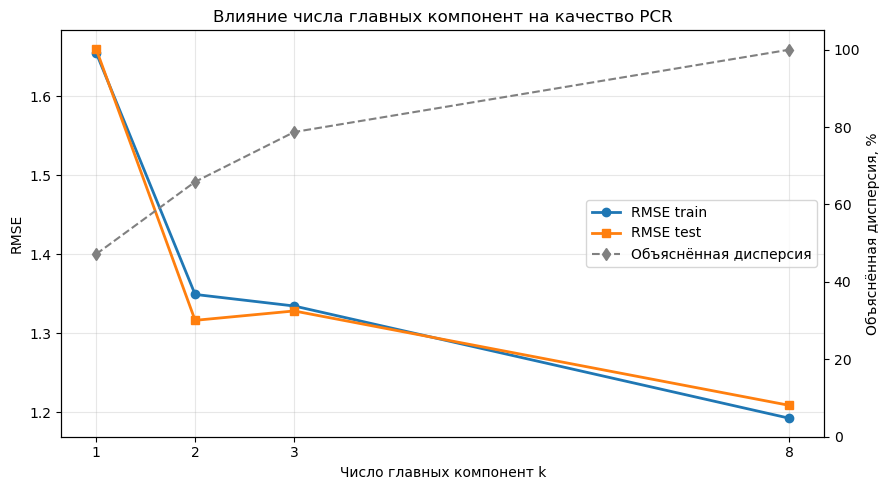

In [19]:
fig, ax1 = plt.subplots(figsize=(9, 5))

# Ошибка регрессии
ax1.plot(
    pcr_results["k"],
    pcr_results["RMSE_train"],
    "o-",
    label="RMSE train",
    linewidth=2
)

ax1.plot(
    pcr_results["k"],
    pcr_results["RMSE_test"],
    "s-",
    label="RMSE test",
    linewidth=2
)

ax1.set_xlabel("Число главных компонент k")
ax1.set_ylabel("RMSE")
ax1.set_xticks(k_values)
ax1.grid(alpha=0.3)

# Объяснённая дисперсия на второй оси
ax2 = ax1.twinx()

ax2.plot(
    pcr_results["k"],
    pcr_results["EVR"] * 100,
    "d--",
    color="gray",
    label="Объяснённая дисперсия",
    linewidth=1.5
)

ax2.set_ylabel("Объяснённая дисперсия, %")
ax2.set_ylim(0, 105)

# Общая легенда
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")

plt.title("Влияние числа главных компонент на качество PCR")
plt.tight_layout()
plt.show()


#### 6.4. Выводы

Исследована регрессия на главных компонентах (PCR) с сохранением $k=1,2,3,8$ компонент.

С увеличением $k$ доля объяснённой дисперсии признаков возрастает с $47.16\%$ до $100\%$, а обусловленность редуцированной задачи ухудшается: $\kappa_2(X_k)$ увеличивается с $1.00$ до $7.08$, $\kappa_2(X_k^TX_k)$ — с $1.00$ до $50.10$.

Тестовая RMSE изменяется немонотонно: при переходе от $k=2$ к $k=3$ ошибка увеличивается с $1.316$ до $1.328$, несмотря на рост объяснённой дисперсии с $65.86\%$ до $78.73\%$.

Наименьшая тестовая RMSE среди рассмотренных моделей получена при $k=8$ ($1.209$). При этом полное PCR-решение практически совпадает с обычным МНК: норма разности коэффициентов составляет $7.50\cdot10^{-15}$.

Таким образом, сокращение размерности улучшает обусловленность задачи, но в данном эксперименте сопровождается ухудшением точности прогнозирования по сравнению с полной моделью.




### 7. Гребневая регрессия (Ridge Regression)

#### 7.1. Теоретические основы

Обычный метод наименьших квадратов минимизирует сумму квадратов ошибок:

$$
\min_\beta\|X\beta-y\|_2^2.
$$

При плохой обусловленности матрицы $X$ решение может содержать большие и численно неустойчивые коэффициенты.

**Гребневая регрессия (Ridge Regression)** добавляет штраф за величину коэффициентов:

$$
\boxed{
\min_{\beta_0,\beta}
\left(
\|y-\beta_0\mathbf{1}-X\beta\|_2^2
+\lambda\|\beta\|_2^2
\right)
}
$$

где $\lambda\geq0$ — параметр регуляризации. Свободный член $\beta_0$ не штрафуется.

Поскольку признаки стандартизованы и центрированы, оптимальный свободный член равен $\bar y_{\mathrm{train}}$. Для центрированного вектора $y_c=y-\bar y_{\mathrm{train}}$ задача принимает вид:

$$
\min_\beta\left(\|X\beta-y_c\|_2^2+\lambda\|\beta\|_2^2\right).
$$

Приравнивая градиент целевой функции к нулю, получаем:

$$
-2X^T(y_c-X\beta)+2\lambda\beta=0.
$$

Следовательно,

$$
(X^TX+\lambda I)\beta=X^Ty_c,
$$

откуда

$$
\boxed{\beta_{\mathrm{Ridge}}=(X^TX+\lambda I)^{-1}X^Ty_c}.
$$

На практике обратную матрицу явно не вычисляют, а решают соответствующую линейную систему.

**Влияние параметра $\lambda$:**

- При $\lambda=0$ получаем обычное МНК.
- При $\lambda>0$ матрица $X^TX+\lambda I$ становится положительно определённой, а коэффициенты регуляризуются.
- При увеличении $\lambda$ нормы коэффициентов уменьшаются, но слишком сильная регуляризация может ухудшить точность модели.

С точки зрения SVD регуляризация изменяет вклад каждого сингулярного направления:

$$
\beta_{\mathrm{Ridge}}
=
\sum_{i=1}^{r}
\frac{\sigma_i}{\sigma_i^2+\lambda}
(u_i^Ty_c)v_i.
$$

В отличие от усечённого SVD, Ridge не исключает отдельные направления полностью, а плавно уменьшает их вклад.

Исследуем несколько значений $\lambda$ и сравним норму коэффициентов, RMSE на обучающей и тестовой выборках, а также обусловленность регуляризованной системы.


#### 7.2. Численное исследование регуляризации

Исследуем Ridge-регрессию при семи значениях параметра регуляризации:

$$
\lambda\in\{0,\;0.01,\;0.1,\;1,\;10,\;100,\;1000\}.
$$

Для каждого $\lambda$ решим систему

$$
(X^TX+\lambda I)\beta=X^Ty_c,
$$

где $X$ — стандартизованная матрица обучающих признаков, $y_c=y_{\mathrm{train}}-\bar y_{\mathrm{train}}$.

Свободный член $\beta_0=\bar y_{\mathrm{train}}$ не регуляризуется.

Сравним:

- число обусловленности регуляризованной матрицы $\kappa_2(X^TX+\lambda I)$;
- норму коэффициентов $\|\beta\|_2$ (без свободного члена);
- RMSE на обучающей и тестовой выборках.

Ожидается, что при увеличении $\lambda$ обусловленность и норма коэффициентов будут уменьшаться, однако чрезмерная регуляризация может приводить к росту ошибки прогнозирования.


**Критерий выбора параметра регуляризации:**

Выберем минимальное значение $\lambda$ из рассматриваемого набора, для которого одновременно выполняются условия:

1. Число обусловленности регуляризованной системы уменьшается не менее чем на $20\%$ относительно $\lambda=0$:

$$
\kappa_2(A_\lambda)\leq 0.8\,\kappa_2(A_0).
$$

2. Обучающая RMSE увеличивается не более чем на $1\%$ относительно нерегуляризованного решения:

$$
\mathrm{RMSE}_{train}(\lambda)
\leq1.01\,\mathrm{RMSE}_{train}(0).
$$

Такой критерий позволяет улучшить численную обусловленность системы, ограничивая ухудшение качества аппроксимации. Тестовая выборка не используется при выборе $\lambda$.



In [20]:
lambda_values = [0, 0.01, 0.1, 1, 10, 100, 1000]

# Стандартизованные признаки без столбца единиц
X_ridge = X_train_std
y_mean = y_train.mean()
y_centered = y_train - y_mean

# Матрица и правая часть нормальных уравнений
A_ridge = X_ridge.T @ X_ridge
b_ridge = X_ridge.T @ y_centered

ridge_results = []
ridge_coefficients = {}

for lam in lambda_values:
    # Регуляризованная матрица
    A_reg = A_ridge + lam * np.eye(X_ridge.shape[1])

    # Решение системы
    beta = np.linalg.solve(A_reg, b_ridge)
    ridge_coefficients[lam] = beta

    # Предсказания
    y_pred_train = y_mean + X_train_std @ beta
    y_pred_test = y_mean + X_test_std @ beta

    # Метрики
    rmse_train = np.sqrt(np.mean((y_train - y_pred_train) ** 2))
    rmse_test = np.sqrt(np.mean((y_test - y_pred_test) ** 2))

    ridge_results.append({
        "lambda": lam,
        "cond_A": np.linalg.cond(A_reg),
        "beta_norm": np.linalg.norm(beta),
        "RMSE_train": rmse_train,
        "RMSE_test": rmse_test
    })

ridge_results = pd.DataFrame(ridge_results)
display(ridge_results)

# Проверка: lambda=0 соответствует обычному МНК
beta_ridge_0 = np.r_[y_mean, ridge_coefficients[0]]

print(
    "Норма разности коэффициентов Ridge (λ=0) и LU:",
    f"{np.linalg.norm(beta_ridge_0 - beta_lu):.3e}"
)


# Выбор lambda по заранее заданному критерию
baseline = ridge_results.iloc[0]

candidates = ridge_results[
    (ridge_results["cond_A"] <= 0.8 * baseline["cond_A"])
    & (ridge_results["RMSE_train"] <= 1.01 * baseline["RMSE_train"])
]

if not candidates.empty:
    selected_lambda = candidates["lambda"].min()
    selected_result = ridge_results[
        ridge_results["lambda"] == selected_lambda
    ]

    print(f"Выбранное lambda: {selected_lambda:g}")
    display(selected_result)
else:
    selected_lambda = None
    print("Ни одно значение lambda не удовлетворяет критерию.")



,lambda,cond_A,beta_norm,RMSE_train,RMSE_test
0,0.00,50.099220,2.027168,1.192644,1.208936
1,0.01,50.084271,2.026699,1.192644,1.208927
2,0.10,49.950135,2.022492,1.192645,1.208850
3,1.00,48.648029,1.981714,1.192730,1.208175
4,10.00,38.636475,1.672309,1.198155,1.207483
5,100.00,13.136306,0.904102,1.262706,1.259391
6,1000.00,2.560862,0.331909,1.448006,1.458610


Норма разности коэффициентов Ridge (λ=0) и LU: 6.686e-15
Выбранное lambda: 10


,lambda,cond_A,beta_norm,RMSE_train,RMSE_test
4,10.0,38.636475,1.672309,1.198155,1.207483


#### 7.3. Анализ влияния параметра регуляризации

Для визуального анализа построим зависимости RMSE на обучающей и тестовой выборках, а также нормы коэффициентов $\|\beta\|_2$ от параметра регуляризации $\lambda$.

Поскольку значения $\lambda$ изменяются в широком диапазоне, используем симметричную логарифмическую шкалу, позволяющую отобразить также $\lambda=0$.

График позволит оценить компромисс между уменьшением нормы коэффициентов и сохранением точности прогнозирования.


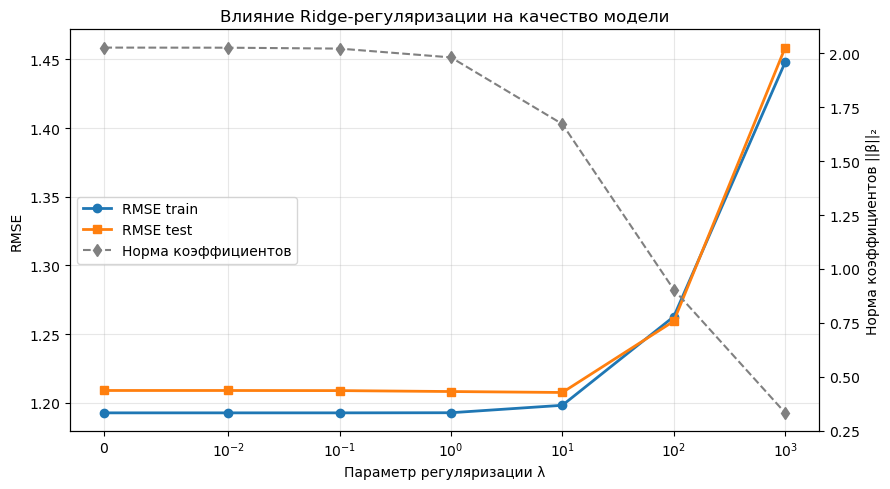

In [21]:
fig, ax1 = plt.subplots(figsize=(9, 5))

# Ошибки предсказания
ax1.plot(
    ridge_results["lambda"],
    ridge_results["RMSE_train"],
    "o-",
    linewidth=2,
    label="RMSE train"
)

ax1.plot(
    ridge_results["lambda"],
    ridge_results["RMSE_test"],
    "s-",
    linewidth=2,
    label="RMSE test"
)

ax1.set_xlabel("Параметр регуляризации λ")
ax1.set_ylabel("RMSE")
ax1.set_xscale("symlog", linthresh=0.01)
ax1.grid(alpha=0.3)

# Норма коэффициентов
ax2 = ax1.twinx()

ax2.plot(
    ridge_results["lambda"],
    ridge_results["beta_norm"],
    "d--",
    color="gray",
    linewidth=1.5,
    label="Норма коэффициентов"
)

ax2.set_ylabel("Норма коэффициентов ||β||₂")

# Общая легенда
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="center left")

plt.title("Влияние Ridge-регуляризации на качество модели")
plt.tight_layout()
plt.show()


#### 7.4. Выводы

Исследовано влияние Ridge-регуляризации при семи значениях $\lambda$ от $0$ до $1000$.

С увеличением $\lambda$ число обусловленности регуляризованной матрицы уменьшилось с $50.10$ до $2.56$, а норма коэффициентов — с $2.027$ до $0.332$. Это подтверждает стабилизирующее действие регуляризации.

По заранее установленному критерию выбрано $\lambda=10$: число обусловленности уменьшилось на $22.9\%$, а обучающая RMSE увеличилась лишь на $0.46\%$. При этом норма коэффициентов снизилась на $17.5\%$.

Для выбранного значения $\lambda$ тестовая RMSE составила $1.2075$ против $1.2089$ у обычного МНК. Таким образом, умеренная регуляризация незначительно улучшила качество прогнозирования. При $\lambda=100$ и $1000$ наблюдался существенный рост RMSE, свидетельствующий о чрезмерной регуляризации.

Таким образом, Ridge позволяет улучшить обусловленность системы и уменьшить норму коэффициентов, однако слишком сильная регуляризация ухудшает точность модели.



### 8. Итоговое сравнение методов

Сопоставим результаты решения исходной задачи МНК на стандартизованной матрице признаков методами LU, Холецкого, Зейделя, SVD, PCR с полным числом компонент и Ridge-регрессии с выбранным параметром $\lambda=10$.

Для каждого метода сравним:

- относительный остаток исходной задачи МНК $r_{\mathrm{LS}}$;
- RMSE на обучающей и тестовой выборках;
- норму разности коэффициентов относительно решения SVD:

$$
\Delta_\beta=\|\beta-\beta_{\mathrm{SVD}}\|_2.
$$

Дополнительно для нерегуляризованных методов сравним относительный остаток нормальных уравнений:

$$
r_{\mathrm{NE}}=\frac{\|X^TX\beta-X^Ty\|_2}{\|X^Ty\|_2}.
$$

Для Ridge этот показатель не рассматривается, поскольку метод решает регуляризованные нормальные уравнения.

Результаты эксперимента с искусственно ухудшенной обусловленностью рассматриваются отдельно в разделе 5.


In [22]:
# Решения исходной задачи
final_solutions = {
    "LU": beta_lu,
    "Cholesky": beta_chol,
    "Gauss-Seidel": beta_gs,
    "SVD": beta_svd,
    "PCR (k=8)": beta_pcr_full,
    f"Ridge (λ={selected_lambda:g})": np.r_[
        y_train.mean(),
        ridge_coefficients[selected_lambda]
    ]
}

# Итоговые метрики
final_rows = []

for name, beta in final_solutions.items():
    if beta is None:
        continue

    metrics = evaluate_solution(beta)

    final_rows.append({
        "Метод": name,
        "r_NE": (
            metrics["r_NE"]
            if not name.startswith("Ridge") else np.nan
        ),
        "r_LS": metrics["r_LS"],
        "RMSE_train": metrics["RMSE_train"],
        "RMSE_test": metrics["RMSE_test"],
        "Δβ_SVD": np.linalg.norm(beta - beta_svd)
    })

final_comparison = pd.DataFrame(final_rows).set_index("Метод")

display(final_comparison)


,r_NE,r_LS,RMSE_train,RMSE_test,Δβ_SVD
Метод,,,,,
LU,1.140120e-16,0.239522,1.192644,1.208936,8.038882e-15
Cholesky,1.432983e-16,0.239522,1.192644,1.208936,8.064332e-15
Gauss-Seidel,8.640753e-11,0.239522,1.192644,1.208936,3.207655e-09
SVD,1.445517e-15,0.239522,1.192644,1.208936,0.000000e+00
PCR (k=8),1.310986e-15,0.239522,1.192644,1.208936,1.938375e-15
Ridge (λ=10),NaN,0.240629,1.198155,1.207483,4.046391e-01



#### 8.1. Выводы

Прямые методы LU и Холецкого, итерационный метод Зейделя и спектральные методы SVD и PCR ($k=8$) дали практически идентичные решения исходной задачи МНК. Для всех методов тестовая RMSE составила $1.208936$, а относительный остаток МНК — $0.239522$.

Наименьшие остатки нормальных уравнений получены методами LU и Холецкого (порядка $10^{-16}$). Для SVD и PCR остатки составили порядка $10^{-15}$, а для метода Зейделя — $8.64\cdot10^{-11}$ вследствие остановки итераций при заданном допуске. При этом различия в коэффициентах практически не повлияли на качество прогнозирования.

Ridge-регрессия при выбранном $\lambda=10$ обеспечила несколько меньшую тестовую RMSE ($1.207483$), несмотря на увеличение относительного остатка исходной задачи МНК до $0.240629$. Отличие коэффициентов от SVD объясняется действием регуляризации.

Таким образом, для исходной хорошо обусловленной матрицы все нерегуляризованные методы оказались практически эквивалентны по точности. Ridge позволила немного улучшить тестовую ошибку, а SVD остаётся предпочтительным универсальным способом решения с точки зрения обработки возможной потери ранга.


### 9. Общие выводы

В работе исследованы численные методы решения задачи наименьших квадратов на наборе данных QSAR Aquatic Toxicity. Получены следующие результаты:

1. **Влияние стандартизации.** Стандартизация количественных признаков уменьшила число обусловленности матрицы $\kappa_2(X)$ с $605.37$ до $7.08$, а нормальных уравнений $\kappa_2(X^TX)$ — с $3.66\cdot10^5$ до $50.10$. Ранг матрицы остался равным 9. Улучшение обусловленности создало благоприятные условия для численного решения задачи.

2. **Сравнение методов решения.** Методы LU, Холецкого, Зейделя и SVD дали практически идентичные коэффициенты и тестовую RMSE $1.208936$. Норма разности коэффициентов LU и SVD составила $8.04\cdot10^{-15}$, а Зейделя и SVD — $3.21\cdot10^{-9}$. Более заметное расхождение итерационного метода объясняется его остановкой при заданном допуске.

3. **Сходимость метода Зейделя.** Спектральный радиус итерационной матрицы составил $\rho(B_{\mathrm{GS}})=0.843002<1$, что гарантирует сходимость. Метод сошёлся за 118 итераций, достигнув относительного остатка $8.64\cdot10^{-11}$. Среднее отношение последовательных остатков на последних 20 итерациях составило $0.843003$, практически совпав со спектральным радиусом.

4. **Ухудшение обусловленности.** При добавлении почти линейно зависимого признака с $\varepsilon=10^{-6}$ число обусловленности матрицы достигло $3.62\cdot10^6$, а нормы коэффициентов LU и SVD возросли примерно до $6.5\cdot10^4$. Несмотря на это, относительный остаток МНК сохранился около $0.2394$, а тестовая RMSE — около $1.210$. При $\varepsilon=0$ матрица потеряла полный столбцовый ранг, и относительное расхождение коэффициентов LU и SVD достигло $6.13\%$, хотя качество прогнозирования осталось практически одинаковым.

5. **Сокращение размерности.** PCR с сохранением $k=1,2,3,8$ компонент показала, что уменьшение числа компонент улучшает обусловленность, но может снижать точность прогнозирования. Например, при $k=2$ число обусловленности редуцированной матрицы составило $1.59$ против $7.08$ при $k=8$, однако тестовая RMSE увеличилась с $1.209$ до $1.316$. Наименьшая ошибка среди рассмотренных моделей получена при использовании всех восьми компонент. Кроме того, увеличение объяснённой дисперсии не всегда сопровождалось снижением тестовой RMSE.

6. **Ridge-регуляризация.** При увеличении $\lambda$ от 0 до 1000 число обусловленности регуляризованной системы уменьшилось с $50.10$ до $2.56$, а норма коэффициентов — с $2.027$ до $0.332$. По заранее заданному критерию выбрано $\lambda=10$: обусловленность улучшилась на $22.9\%$ при увеличении обучающей RMSE всего на $0.46\%$. Тестовая RMSE для выбранной модели составила $1.2075$, что незначительно лучше нерегуляризованного решения ($1.2089$).

7. **Выбор метода решения.** Для исходной хорошо обусловленной задачи прямые методы и SVD оказались практически эквивалентны по точности. Однако SVD не требует формирования нормальных уравнений и позволяет корректно обрабатывать потерю ранга. Поэтому в качестве наиболее универсального и численно устойчивого способа решения исследованной задачи целесообразно выбрать SVD. LU может использоваться как эффективная альтернатива для матриц полного ранга, а Ridge — для дополнительной стабилизации коэффициентов.

Таким образом, результаты подтвердили существенное влияние обусловленности и ранга матрицы на устойчивость коэффициентов регрессии. При этом качество прогнозирования может оставаться практически неизменным даже при сильной мультиколлинеарности. Применение сокращения размерности и регуляризации требует компромисса между численной устойчивостью и точностью модели.

